## Task 1: Import libraries and load the dataset

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score
)

df = pd.read_csv("Airline Data.csv")
print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully.
Shape: (129880, 22)
Columns: ['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']


## Task 2: Display the first five records

In [24]:
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


## Task 3: Inspect the dataset

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    1298

In [26]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,129880,2,Female,65899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Type,129880,2,Loyal Customer,106100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,129880.0,NaN,NaN,NaN,39.427957,15.11936,7.0,27.0,40.0,51.0,85.0
Type of Travel,129880,2,Business travel,89693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,129880,3,Business,62160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,129880.0,NaN,NaN,NaN,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Inflight wifi service,129880.0,NaN,NaN,NaN,2.728696,1.32934,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,NaN,NaN,NaN,3.057599,1.526741,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,129880.0,NaN,NaN,NaN,2.756876,1.40174,0.0,2.0,3.0,4.0,5.0
Gate location,129880.0,NaN,NaN,NaN,2.976925,1.27852,0.0,2.0,3.0,4.0,5.0


## Task 4: Check missing values and duplicate rows

In [27]:
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False))
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nTarget distribution:")
print(df["satisfaction"].value_counts(dropna=False))

Missing values per column:
Arrival Delay in Minutes             393
Gender                                 0
Age                                    0
Type of Travel                         0
Class                                  0
Customer Type                          0
Flight Distance                        0
Inflight wifi service                  0
Ease of Online booking                 0
Departure/Arrival time convenient      0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Gate location                          0
Inflight entertainment                 0
On-board service                       0
Baggage handling                       0
Leg room service                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
satisfaction                           0
dtype: int64
\nDuplicate rows: 0
\nTarget distribution:
satisfaction
Fa

## Task 5: Clean the data

Remove exact duplicate rows and rows without a target label. The target column is converted to a consistent binary label. The input columns are kept as predictors; preprocessing for missing values and categorical variables is fitted only on training data through a pipeline.

In [28]:
df = df.drop_duplicates().copy()
df = df.dropna(subset=["satisfaction"]).copy()

# Normalize target values to strings, then map common labels to 0/1.
target_text = df["satisfaction"].astype(str).str.strip().str.lower()
target_map = {
    "true": 1, "1": 1, "yes": 1, "satisfied": 1,
    "false": 0, "0": 0, "no": 0, "neutral or dissatisfied": 0
}
y = target_text.map(target_map)

# Stop clearly if the CSV uses unexpected target labels.
if y.isna().any():
    raise ValueError("Unexpected labels in 'satisfaction': " +
                     str(sorted(target_text[y.isna()].unique())))

# Avoid including the target in the features.
X = df.drop(columns=["satisfaction"])
print("Cleaned dataset shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("Target counts (0 = not satisfied, 1 = satisfied):")
print(y.value_counts().sort_index())

Cleaned dataset shape: (129880, 22)
Feature matrix shape: (129880, 21)
Target counts (0 = not satisfied, 1 = satisfied):
satisfaction
0    73452
1    56428
Name: count, dtype: int64


## Task 6: Identify numeric and categorical features

In [29]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("\\nCategorical features:", categorical_features)

Numeric features: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
\nCategorical features: ['Gender', 'Customer Type', 'Type of Travel', 'Class']


## Task 7: Split data into training and testing sets (80/20)

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training labels  :", y_train.shape)
print("Testing labels   :", y_test.shape)

Training features: (103904, 21)
Testing features : (25976, 21)
Training labels  : (103904,)
Testing labels   : (25976,)


## Task 8: Build preprocessing and the ANN

Numeric columns are imputed with their median and standardized. Categorical columns are imputed with the most frequent value and one-hot encoded. The ANN is an `MLPClassifier` with two hidden layers. Early stopping helps limit overfitting.

In [31]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    onehot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn versions
    onehot_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot_encoder)
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

ann = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=5,
    random_state=42,
    verbose=True
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("ann", ann)
])

model.fit(X_train, y_train)
print("ANN training complete.")
print("Training iterations:", model.named_steps["ann"].n_iter_)

Iteration 1, loss = 0.28299875
Validation score: 0.927630
Iteration 2, loss = 0.16856769
Validation score: 0.938312
Iteration 3, loss = 0.14832114
Validation score: 0.943509
Iteration 4, loss = 0.13574157
Validation score: 0.944856
Iteration 5, loss = 0.12607941
Validation score: 0.946492
Iteration 6, loss = 0.11997356
Validation score: 0.951304
Iteration 7, loss = 0.11410242
Validation score: 0.954961
Iteration 8, loss = 0.11052963
Validation score: 0.953517
Iteration 9, loss = 0.10671027
Validation score: 0.954672
Iteration 10, loss = 0.10461172
Validation score: 0.955731
Iteration 11, loss = 0.10221902
Validation score: 0.956308
Iteration 12, loss = 0.10064476
Validation score: 0.955731
Iteration 13, loss = 0.09887579
Validation score: 0.956886
Iteration 14, loss = 0.09745113
Validation score: 0.956790
Iteration 15, loss = 0.09621105
Validation score: 0.957367
Iteration 16, loss = 0.09520684
Validation score: 0.953421
Iteration 17, loss = 0.09425565
Validation score: 0.957078
Iterat

## Task 9: Predict passenger satisfaction

In [32]:
y_pred = model.predict(X_test)
results = pd.DataFrame({
    "Actual satisfaction": y_test.map({0: "Not satisfied", 1: "Satisfied"}).to_numpy(),
    "Predicted satisfaction": pd.Series(y_pred).map({0: "Not satisfied", 1: "Satisfied"}).to_numpy()
})
results.head(10)

,Actual satisfaction,Predicted satisfaction
0,Not satisfied,Not satisfied
1,Not satisfied,Not satisfied
2,Satisfied,Satisfied
3,Not satisfied,Not satisfied
4,Satisfied,Satisfied
5,Not satisfied,Not satisfied
6,Satisfied,Satisfied
7,Not satisfied,Not satisfied
8,Satisfied,Satisfied
9,Not satisfied,Not satisfied


## Task 10: Evaluate the ANN model

In [33]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Not satisfied", "Satisfied"],
    zero_division=0
))

if len(np.unique(y_test)) == 2:
    y_prob = model.predict_proba(X_test)[:, 1]
    print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

Accuracy: 0.9548 (95.48%)
\nClassification report:
               precision    recall  f1-score   support

Not satisfied       0.95      0.97      0.96     14690
    Satisfied       0.96      0.94      0.95     11286

     accuracy                           0.95     25976
    macro avg       0.96      0.95      0.95     25976
 weighted avg       0.95      0.95      0.95     25976

ROC-AUC: 0.9932


## Task 11: Plot the confusion matrix

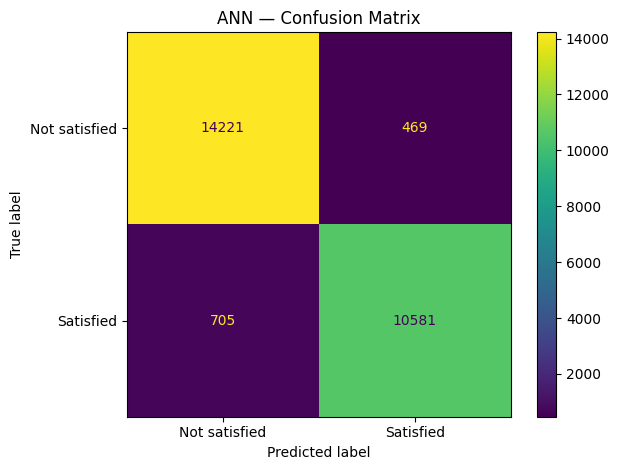

In [34]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not satisfied", "Satisfied"]
)
disp.plot(values_format="d")
plt.title("ANN — Confusion Matrix")
plt.tight_layout()
plt.show()

## Task 12: Plot the ANN training loss

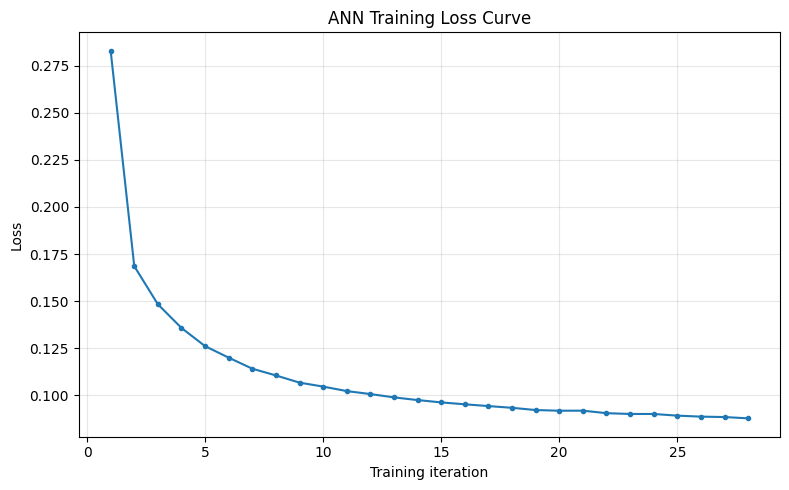

In [35]:
loss_curve = model.named_steps["ann"].loss_curve_
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_curve) + 1), loss_curve, marker="o", markersize=3)
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.title("ANN Training Loss Curve")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Task 13: Interpret the results

In [36]:
print(f"The model correctly classified {accuracy * 100:.2f}% of the test passengers.")
print("Use the precision, recall, F1-score, and confusion matrix above to check")
print("how well the ANN predicts each satisfaction class.")
print("A high accuracy alone may not tell the full story if class counts differ.")

The model correctly classified 95.48% of the test passengers.
Use the precision, recall, F1-score, and confusion matrix above to check
how well the ANN predicts each satisfaction class.
A high accuracy alone may not tell the full story if class counts differ.


## Task 14: Predict satisfaction for a sample passenger

In [37]:
# Start with a real test passenger so every required feature is present.
sample_passenger = X_test.iloc[[0]].copy()
predicted_class = int(model.predict(sample_passenger)[0])
probabilities = model.predict_proba(sample_passenger)[0]

print("Predicted satisfaction:",
      "Satisfied" if predicted_class == 1 else "Not satisfied")
print(f"Probability not satisfied: {probabilities[0]:.3f}")
print(f"Probability satisfied    : {probabilities[1]:.3f}")

Predicted satisfaction: Not satisfied
Probability not satisfied: 0.999
Probability satisfied    : 0.001


## Task 15: Save the trained ANN pipeline (optional)

In [38]:
import joblib

joblib.dump(model, "airline_satisfaction_ann.joblib")
print("Saved model to airline_satisfaction_ann.joblib")

Saved model to airline_satisfaction_ann.joblib


Gradio Interface


In [39]:
!pip install gradio

In [22]:
import gradio as gr
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Load + clean (put the CSV next to this file as data.csv)
df = pd.read_csv("Airline Data.csv").drop_duplicates().dropna(subset=["satisfaction"])
y = df.pop("satisfaction").astype(str).str.lower().eq("true").astype(int)
num = df.select_dtypes("number").columns.tolist()
cat = df.select_dtypes(exclude="number").columns.tolist()

# Preprocessing + ANN
pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
])
model = make_pipeline(pre, MLPClassifier((64, 32), early_stopping=True, max_iter=30, random_state=42))
X_tr, X_te, y_tr, y_te = train_test_split(df, y, test_size=0.2, random_state=42, stratify=y)
model.fit(X_tr, y_tr)
print(f"Test accuracy: {model.score(X_te, y_te):.4f}")

# Gradio UI (inputs are built from the columns automatically)
inputs = [gr.Dropdown(sorted(df[c].unique().tolist()), value=df[c].mode()[0], label=c) for c in cat] + \
         [gr.Number(value=float(df[c].median()), label=c) for c in num]

def predict(*vals):
    p = model.predict_proba(pd.DataFrame([vals], columns=cat + num))[0]
    return {"Not satisfied": float(p[0]), "Satisfied": float(p[1])}

gr.Interface(predict, inputs, gr.Label(), title="Airline Passenger Satisfaction").launch()

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Test accuracy: 0.9567
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5755e13ee074c8aaa7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
